# 11 - Fairness Check

`CODE_GENDER` and `NAME_FAMILY_STATUS` were excluded from every model ("fairness through unawareness"), and `AGE_YEARS` is used by LGBM-full but not by the scorecard. Excluding an attribute does not guarantee fair outcomes: other features can act as proxies, and when groups have different default rates a blind model can still treat them differently.

This notebook checks outcomes on the test set at cut-off 550, by **gender** and **age band**:

| Metric | Question |
|---|---|
| `approval_rate`, **disparate impact** | Is one group approved much less often? (four-fifths rule: ratio < 0.8 is a red flag) |
| `good_approval_rate` | Among applicants who did *not* default, is approval equal? (equal opportunity) |
| `calib_ratio` = default rate / mean PD | Is risk over-estimated (< 1) or under-estimated (> 1) for a group? |
| `auc` | Does the model rank equally well within each group? |

Plus a **proxy check**: how well the model features predict gender.

These criteria cannot all be met at once when base rates differ; the goal is to measure and document, not to optimise one number.

## 1. Setup

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.explain import lgbm_contributions, mean_abs_importance
from src.fairness import age_bands, disparate_impact, group_metrics, proxy_auc
from src.gbm import prepare_features
from src.scorecard import pd_to_score

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CUTOFF = 550
MODELS = ["Scorecard", "LGBM-16", "LGBM-16-mono", "LGBM-full"]

COLORS = {"Scorecard": "#2a78d6", "LGBM-16": "#eb6834", "LGBM-16-mono": "#1baf7a", "LGBM-full": "#eda100"}
MUTED, GRID = "#8a8985", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## 2. Load scores and protected attributes

In [2]:
train = pd.read_pickle(DATA_DIR / "train.pkl")
test = pd.read_pickle(DATA_DIR / "test.pkl")
pd_test = pd.read_pickle(DATA_DIR / "pd_test_all_models.pkl")
y_test = test["TARGET"]

scaling = pd.read_csv(OUTPUT_DIR / "score_scaling.csv", index_col=0).iloc[:, 0]
scores = {m: pd_to_score(pd_test[m], scaling["factor"], scaling["offset"]) for m in MODELS}

gender = test["CODE_GENDER"]
age = age_bands(test["AGE_YEARS"])
print(gender.value_counts(dropna=False).to_string(), "\n")
print(pd.DataFrame({"n": age.value_counts().sort_index(),
                    "default_rate": y_test.groupby(age, observed=True).mean().round(4)}))

CODE_GENDER
F      40561
M      20940
NaN        2 

              n  default_rate
age_band                     
<25        2390        0.1172
25-34     14355        0.1053
35-44     16897        0.0828
45-54     14039        0.0734
55+       13822        0.0538


## 3. Gender

Default rates differ by gender, so equal approval rates and equal calibration cannot both hold. Disparate impact uses the group with the highest approval rate as reference.

In [3]:
def fairness_table(group: pd.Series) -> pd.DataFrame:
    """Group metrics for every model, with disparate impact of approval rates."""
    parts = []
    for m in MODELS:
        t = group_metrics(y_test, pd_test[m], scores[m], group, CUTOFF)
        t["disparate_impact"] = disparate_impact(t["approval_rate"])
        t["good_approval_di"] = disparate_impact(t["good_approval_rate"])
        parts.append(t.assign(model=m))
    out = pd.concat(parts).rename_axis("group").reset_index().set_index(["model", "group"])
    return out


fair_gender = fairness_table(gender)
fair_gender.round(3)

n  default_rate  mean_pd  calib_ratio  mean_score  \
model        group                                                          
Scorecard    F      40561         0.070    0.075        0.930     569.087   
             M      20940         0.102    0.091        1.122     563.078   
LGBM-16      F      40561         0.070    0.074        0.951     570.243   
             M      20940         0.102    0.094        1.087     562.761   
LGBM-16-mono F      40561         0.070    0.074        0.947     570.004   
             M      20940         0.102    0.093        1.088     562.866   
LGBM-full    F      40561         0.070    0.073        0.954     571.108   
             M      20940         0.102    0.094        1.083     563.466   

                    approval_rate  good_approval_rate    auc  \
model        group                                             
Scorecard    F              0.763               0.787  0.734   
             M              0.681               0.716  0.736   
LGBM-16      F              0.785               0.809  0.744   
             M              0.686               0.724  0.750   
LGBM-16-mono F              0.790               0.813  0.738   
             M              0.691               0.727  0.746   
LGBM-full    F              0.789               0.813  0.751   
             M              0.692               0.731  0.761   

                    disparate_impact  good_approval_di  
model        group                                      
Scorecard    F                 1.000             1.000  
             M                 0.893             0.910  
LGBM-16      F                 1.000             1.000  
             M                 0.875             0.895  
LGBM-16-mono F                 1.000             1.000  
             M                 0.876             0.895  
LGBM-full    F                 1.000             1.000  
             M                 0.877             0.899

## 4. Age band

The scorecard does not use age; LGBM-full does. Young applicants default more often, so lower approval for them is expected; the question is how large the gap is and whether calibration holds.

In [4]:
fair_age = fairness_table(age)
fair_age.round(3)

n  default_rate  mean_pd  calib_ratio  mean_score  \
model        group                                                          
Scorecard    <25     2390         0.117    0.158        0.741     540.776   
             25-34  14355         0.105    0.106        0.993     556.793   
             35-44  16897         0.083    0.079        1.049     567.050   
             45-54  14039         0.073    0.071        1.031     569.865   
             55+    13822         0.054    0.051        1.044     579.346   
LGBM-16      <25     2390         0.117    0.144        0.813     545.654   
             25-34  14355         0.105    0.105        1.005     558.423   
             35-44  16897         0.083    0.079        1.050     568.156   
             45-54  14039         0.073    0.072        1.017     570.420   
             55+    13822         0.054    0.054        0.994     577.806   
LGBM-16-mono <25     2390         0.117    0.155        0.757     543.068   
             25-34  14355         0.105    0.105        1.003     558.134   
             35-44  16897         0.083    0.078        1.067     568.577   
             45-54  14039         0.073    0.073        1.011     570.177   
             55+    13822         0.054    0.054        0.998     577.740   
LGBM-full    <25     2390         0.117    0.126        0.928     550.871   
             25-34  14355         0.105    0.106        0.995     559.118   
             35-44  16897         0.083    0.082        1.005     567.983   
             45-54  14039         0.073    0.072        1.025     571.274   
             55+    13822         0.054    0.052        1.031     579.131   

                    approval_rate  good_approval_rate    auc  \
model        group                                             
Scorecard    <25            0.333               0.363  0.711   
             25-34          0.595               0.632  0.733   
             35-44          0.742               0.771  0.746   
             45-54          0.786               0.810  0.739   
             55+            0.891               0.902  0.688   
LGBM-16      <25            0.445               0.481  0.718   
             25-34          0.629               0.668  0.749   
             35-44          0.760               0.790  0.753   
             45-54          0.789               0.815  0.753   
             55+            0.882               0.894  0.704   
LGBM-16-mono <25            0.412               0.445  0.719   
             25-34          0.633               0.671  0.743   
             35-44          0.770               0.798  0.749   
             45-54          0.791               0.817  0.748   
             55+            0.891               0.902  0.695   
LGBM-full    <25            0.523               0.561  0.725   
             25-34          0.637               0.677  0.759   
             35-44          0.748               0.779  0.763   
             45-54          0.796               0.821  0.757   
             55+            0.889               0.902  0.712   

                    disparate_impact  good_approval_di  
model        group                                      
Scorecard    <25               0.374             0.402  
             25-34             0.668             0.701  
             35-44             0.833             0.855  
             45-54             0.881             0.898  
             55+               1.000             1.000  
LGBM-16      <25               0.505             0.538  
             25-34             0.714             0.747  
             35-44             0.862             0.883  
             45-54             0.894             0.911  
             55+               1.000             1.000  
LGBM-16-mono <25               0.462             0.493  
             25-34             0.711             0.744  
             35-44             0.864             0.885  
             45-54             0.889             0.905  
        

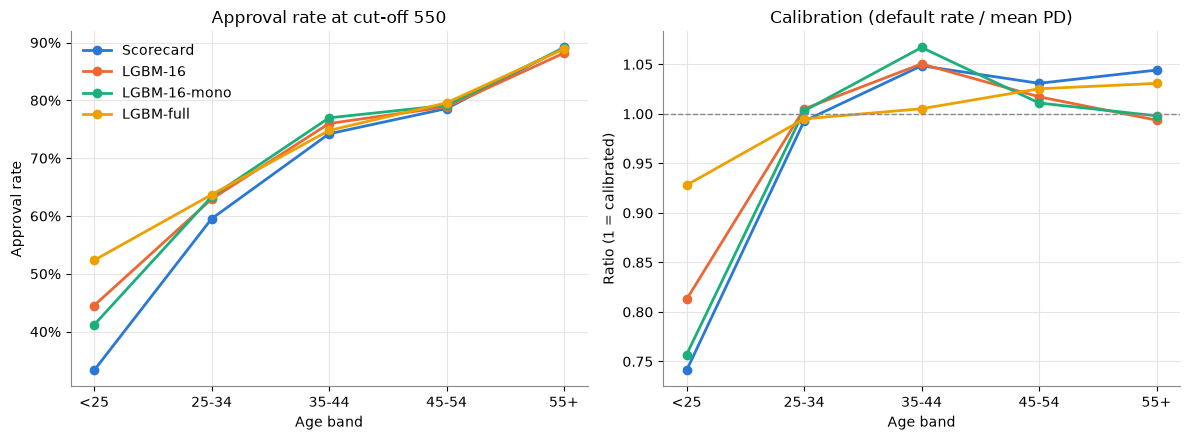

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bands = age.cat.categories
x = range(len(bands))
for m in MODELS:
    t = fair_age.loc[m].reindex(bands)
    axes[0].plot(x, t["approval_rate"], marker="o", markersize=6, color=COLORS[m], label=m)
    axes[1].plot(x, t["calib_ratio"], marker="o", markersize=6, color=COLORS[m], label=m)
axes[1].axhline(1, color=MUTED, linestyle="--", linewidth=1)
axes[0].set(title=f"Approval rate at cut-off {CUTOFF}", xlabel="Age band", ylabel="Approval rate")
axes[1].set(title="Calibration (default rate / mean PD)", xlabel="Age band", ylabel="Ratio (1 = calibrated)")
for ax in axes:
    ax.set_xticks(list(x), list(bands))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fairness_age.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Proxy check: can the features predict gender?

Train a LightGBM classifier to predict gender (M = 1) from each model's features, on train rows; evaluate on test. AUC 0.5 = no information about gender; the higher, the stronger the proxies. The top features show which ones carry gender.

In [6]:
bundles = {}
for name in ["lgbm_16", "lgbm_full"]:
    with open(OUTPUT_DIR / f"lgbm_{name}.pkl", "rb") as f:
        bundles[name] = pickle.load(f)

known_tr, known_te = train["CODE_GENDER"].notna(), test["CODE_GENDER"].notna()
g_tr = (train.loc[known_tr, "CODE_GENDER"] == "M").astype(int)
g_te = (test.loc[known_te, "CODE_GENDER"] == "M").astype(int)

proxy, proxy_top = {}, {}
for label, name in [("16 scorecard features", "lgbm_16"), ("LGBM-full features", "lgbm_full")]:
    b = bundles[name]
    X_tr = prepare_features(train.loc[known_tr], b["features"], b["levels"])
    X_te = prepare_features(test.loc[known_te], b["features"], b["levels"])
    auc, model = proxy_auc(X_tr, g_tr, X_te, g_te)
    contrib, _ = lgbm_contributions(model, X_te.sample(5000, random_state=0))
    proxy[label] = auc
    proxy_top[label] = mean_abs_importance(contrib).head(8)

print(pd.Series(proxy, name="gender proxy AUC").round(3).to_string())
pd.DataFrame({k: v.index for k, v in proxy_top.items()}, index=range(1, 9))

16 scorecard features    0.878
LGBM-full features       0.903


,16 scorecard features,LGBM-full features
1,OCCUPATION_TYPE,OCCUPATION_TYPE
2,OWN_CAR_AGE,OWN_CAR_AGE
3,ORGANIZATION_TYPE,AMT_INCOME_TOTAL
4,EXT_SOURCE_1,EXT_SOURCE_1
5,FLAG_DOCUMENT_3,ORGANIZATION_TYPE
6,YEARS_ID_PUBLISH,AGE_YEARS
7,YEARS_EMPLOYED,FLAG_DOCUMENT_8
8,AMT_GOODS_PRICE,CNT_FAM_MEMBERS


## 6. Save artifacts

In [7]:
fair_gender.to_csv(OUTPUT_DIR / "fairness_gender.csv")
fair_age.to_csv(OUTPUT_DIR / "fairness_age.csv")
pd.Series(proxy, name="gender_proxy_auc").to_csv(OUTPUT_DIR / "fairness_proxy.csv")
print("Saved fairness_gender.csv, fairness_age.csv, fairness_proxy.csv, fairness_age.png")

Saved fairness_gender.csv, fairness_age.csv, fairness_proxy.csv, fairness_age.png
